In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import seaborn as sns

# Set the style parameters
mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
# plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
# plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.serif"] = ["Computer Modern Roman"]
fontsize= 27
colors = ["tab:red", "tab:blue"]

# Define the output folder path
output_dir = os.path.join(os.getcwd(), 'figures')
os.makedirs(output_dir, exist_ok=True)

In [2]:
# Define the ground truth class sizes (after filtering)
ground_truth_class_sizes = {
    'reference': {5: 323, 6: 249}, 'plant': {5: 181, 6:196}, 'marine': {5: 515, 6: 527}
}
# Define methods
methods = ['hyenadna', 'dnabert2', 'dnaberts', 'revisit', 'uncertaingen']
# Define method labels
method2label = {
    'hyenadna': r"\textsc{HyenaDNA}", 'dnabert2': r"\textsc{DNABERT-2}", 'dnaberts': r"\textsc{DNABERT-S}",
    'revisit': r"\textsc{RevisitKmers}", 'uncertaingen': r"\textsc{UncertainGen} (Ours)"
}
# Define the parameter sizes
method2size = {
    'hyenadna': 6551040, 'dnabert2': 117068544, 'dnaberts': 117074176,
    'revisit': 272448, 'uncertaingen': 272448*2
}
method2f1 = {
    'hyenadna': {'reference': {5: 2, 6: 3}, 'plant': {5: 0, 6: 1}, 'marine': {5: 5, 6: 3} },
    'dnabert2': {'reference': {5: 0, 6: 0}, 'plant': {5: 0, 6: 0}, 'marine': {5: 0, 6: 1} },
    'dnaberts': {'reference': {5: 140, 6: 145}, 'plant': {5: 29, 6: 34}, 'marine': {5: 77, 6: 65} },
    'revisit': {'reference': {5: 126, 6: 128}, 'plant': {5: 29, 6: 28}, 'marine': {5: 112, 6: 125} },
    'uncertaingen': {'reference': {5: 151, 6:151}, 'plant': {5: 44, 6:43}, 'marine': {5: 174, 6:189} }
}

method2average_performance = dict()
for method in methods:
    method2average_performance[method] = 0.
    counter = 0.
    for dataset in method2f1[method]:
        for dataset_id in method2f1[method][dataset]:
            ratio = method2f1[method][dataset][dataset_id] / float(ground_truth_class_sizes[dataset][dataset_id])
            method2average_performance[method] += ratio
            counter += 1.

    method2average_performance[method] /= counter

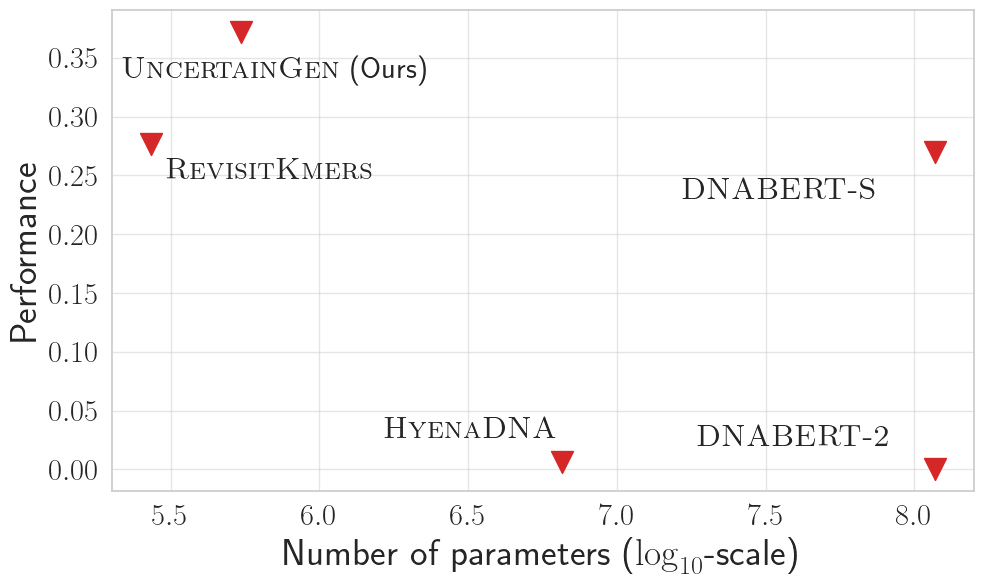

In [10]:
# Plot a scatter plot of parameter size vs average performance
model_sizes = np.asarray([method2size[method] for method in methods])
model_sizes = np.log10(model_sizes)
performance = np.asarray([method2average_performance[method] for method in methods])

colors = ["tab:red", "tab:blue"]
plt.figure(figsize=(10, 6))
plt.scatter(model_sizes, performance, marker='v', s=250, c=colors[0] )
# Add annotates
margins_x, margins_y = [-0.6, -0.8, -0.85, 0.05, -0.4], [0.02, 0.02, -0.04, -0.03, -0.04]
for idx, method in enumerate(methods):
    plt.annotate(
        method2label[method], (model_sizes[idx]+margins_x[idx], performance[idx]+margins_y[idx]),
        fontsize=fontsize-5
    )
# Add axis labels
plt.xlabel("Number of parameters ($\log_{10}$-scale)", fontsize=fontsize)
plt.ylabel("Performance", fontsize=fontsize)
# Adjust the axis font sizes
plt.xticks(fontsize=fontsize-5)
plt.yticks(fontsize=fontsize-5)
# Remove the blank space around the plot
plt.tight_layout()
plt.grid(True, alpha=0.5)
# plt.show()
plt.savefig(os.path.join(output_dir, 'performance_vs_modelsize.png'))
# plt.show()